# 02 · Rule-Based Risk Advisor

An **explainable** system: six IF-THEN rules, based on clinical thresholds, give each patient a risk level and show **which rules fired**, so a nurse or doctor can see *why*.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter

df = pd.read_csv("../data/diabetes_cleaned.csv")
print(df.shape)

(768, 9)


In [2]:
RULES = [
    {"id": "Rule 1", "desc": "Glucose>200 AND BMI>35",      "risk": "HIGH"},
    {"id": "Rule 2", "desc": "Glucose>140 AND Age>40",      "risk": "HIGH"},
    {"id": "Rule 3", "desc": "Glucose>140 AND BMI>30",      "risk": "MEDIUM-HIGH"},
    {"id": "Rule 4", "desc": "BloodPressure>90 AND BMI>30", "risk": "MEDIUM-HIGH"},
    {"id": "Rule 5", "desc": "Age>40 AND BMI>30",           "risk": "MEDIUM"},
    {"id": "Rule 6", "desc": "Glucose<=100 AND BMI<=25",    "risk": "LOW"},
]

def apply_rules(row):
    fired = []
    if row['Glucose'] > 200 and row['BMI'] > 35:      fired.append("Rule 1")
    if row['Glucose'] > 140 and row['Age'] > 40:      fired.append("Rule 2")
    if row['Glucose'] > 140 and row['BMI'] > 30:      fired.append("Rule 3")
    if row['BloodPressure'] > 90 and row['BMI'] > 30: fired.append("Rule 4")
    if row['Age'] > 40 and row['BMI'] > 30:           fired.append("Rule 5")
    if row['Glucose'] <= 100 and row['BMI'] <= 25:    fired.append("Rule 6")

    # Conflict resolution: the highest risk rule wins
    if any(r in fired for r in ["Rule 1", "Rule 2"]):   risk = "HIGH"
    elif any(r in fired for r in ["Rule 3", "Rule 4"]): risk = "MEDIUM-HIGH"
    elif "Rule 5" in fired:                             risk = "MEDIUM"
    elif "Rule 6" in fired:                             risk = "LOW"
    else:                                               risk = "MEDIUM"   # default

    return pd.Series([risk, ", ".join(fired) if fired else "None"])

for r in RULES:
    print(f"{r['id']}: IF {r['desc']} -> {r['risk']}")

Rule 1: IF Glucose>200 AND BMI>35 -> HIGH
Rule 2: IF Glucose>140 AND Age>40 -> HIGH
Rule 3: IF Glucose>140 AND BMI>30 -> MEDIUM-HIGH
Rule 4: IF BloodPressure>90 AND BMI>30 -> MEDIUM-HIGH
Rule 5: IF Age>40 AND BMI>30 -> MEDIUM
Rule 6: IF Glucose<=100 AND BMI<=25 -> LOW


### Apply the rules to all 768 patients

In [3]:
df[['risk_level', 'rules_fired']] = df.apply(apply_rules, axis=1)

dist = df['risk_level'].value_counts()
pd.DataFrame({"Patients": dist, "Percent": (dist / len(df) * 100).round(1)})

,Patients,Percent
risk_level,,
MEDIUM,536,69.8
MEDIUM-HIGH,109,14.2
HIGH,75,9.8
LOW,48,6.2


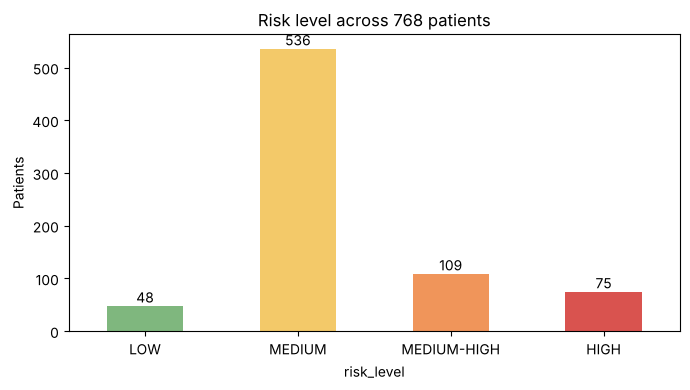

In [4]:
order = ["LOW", "MEDIUM", "MEDIUM-HIGH", "HIGH"]
colors = ["#7fb77e", "#f3c969", "#f0955a", "#d9534f"]
ax = dist.reindex(order).plot(kind="bar", color=colors, figsize=(7, 4), rot=0)
ax.set_title("Risk level across 768 patients")
ax.set_ylabel("Patients")
for p in ax.patches:
    ax.annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig("../images/risk_distribution.png", dpi=150)
plt.show()

### Top 5 HIGH-risk patients and the rules that fired

In [5]:
high_risk = df[df['risk_level'] == 'HIGH'][['Glucose', 'Age', 'BMI', 'BloodPressure', 'risk_level', 'rules_fired']]
high_risk = high_risk.reset_index(drop=True)
high_risk.index += 1
high_risk.head(5)

,Glucose,Age,BMI,BloodPressure,risk_level,rules_fired
1,148,50,33.6,72,HIGH,"Rule 2, Rule 3, Rule 5"
2,197,53,30.5,70,HIGH,"Rule 2, Rule 3, Rule 5"
3,189,59,30.1,60,HIGH,"Rule 2, Rule 3, Rule 5"
4,166,51,25.8,72,HIGH,Rule 2
5,196,41,39.8,90,HIGH,"Rule 2, Rule 3, Rule 5"


### How often each rule fired

In [6]:
all_fired = []
for rules in df['rules_fired']:
    if rules != 'None':
        all_fired.extend([r.strip() for r in rules.split(',')])

freq = Counter(all_fired)
for rule_id, count in sorted(freq.items()):
    desc = next(r['desc'] for r in RULES if r['id'] == rule_id)
    print(f"{rule_id} ({desc}): {count} patients")

Rule 2 (Glucose>140 AND Age>40): 75 patients
Rule 3 (Glucose>140 AND BMI>30): 148 patients
Rule 4 (BloodPressure>90 AND BMI>30): 30 patients
Rule 5 (Age>40 AND BMI>30): 133 patients
Rule 6 (Glucose<=100 AND BMI<=25): 48 patients
